# Exercicio 3 - Estimativa de idade com invariancia em imagens faciais

O objetivo e resolver um problema de regressao de idade usando imagens faciais da base UTKFace, ou uma base equivalente com idade no nome do arquivo, usando uma CNN. A teoria de invariancia e aplicada treinando modelos que devem produzir a mesma idade para transformacoes que preservam a identidade etaria da imagem, como pequenas translacoes, rotacoes, recortes, espelhamento horizontal e mudancas moderadas de cor.

Sao comparados quatro modelos:

1. **Baseline**: CNN treinada apenas com transformacoes deterministicas de pre-processamento.
2. **Data augmentation**: CNN treinada com transformacoes aleatorias que induzem invariancia.
3. **Consistency regularization**: CNN treinada para manter predicoes consistentes entre duas vistas aumentadas da mesma imagem.
4. **Data augmentation + consistency regularization**: combinacao das duas estrategias.

A metrica principal e o MAE, pois o erro absoluto medio em anos e interpretavel diretamente. Tambem reportamos RMSE, que penaliza mais fortemente grandes erros.

## Justificativa da invariancia

Para uma imagem facial $x$ com idade $y$, consideramos uma familia de transformacoes $T$ que nao deve alterar a idade percebida: pequenos recortes, redimensionamentos, rotacoes leves, espelhamento horizontal e perturbacoes moderadas de brilho/contraste/saturacao. A propriedade desejada e

$$f_\theta(T(x)) \approx f_\theta(x).$$

No modelo com data augmentation, essa propriedade e induzida implicitamente, pois a rede observa imagens transformadas com o mesmo rotulo. No modelo com regularizacao de consistencia, ela e imposta explicitamente adicionando a perda

$$\mathcal{L}_{cons} = \frac{1}{B}\sum_{i=1}^{B} \left(f_\theta(T_1(x_i)) - f_\theta(T_2(x_i))\right)^2,$$

em que $T_1$ e $T_2$ sao duas transformacoes estocasticas independentes da mesma imagem. A perda total usada nos modelos com consistencia e

$$\mathcal{L} = \mathcal{L}_{reg} + \lambda_{cons}\mathcal{L}_{cons},$$

com $\mathcal{L}_{reg}$ dada pelo erro quadratico medio entre idade real e idade predita.

In [6]:
from pathlib import Path
import random
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DEVICE

device(type='cuda')

## Preparacao dos dados

A base UTKFace usa nomes no formato aproximado `idade_genero_etnia_data.jpg`. Assim, a idade e extraida do primeiro campo do nome do arquivo. Coloque as imagens em `data/UTKFace`, ou altere a variavel `DATA_DIR`.

Normalizacao usada: imagens RGB redimensionadas para $128\times128$, convertidas para tensores em $[0,1]$ e normalizadas por canal usando media e desvio padrao iguais a `0.5`, isto e, os pixels passam aproximadamente para o intervalo $[-1,1]$.

Como o problema e de regressao, o desbalanceamento foi avaliado por faixas etarias. Em UTKFace normalmente ha concentracao maior em adultos jovens e menos exemplos em criancas pequenas e idosos, o que pode aumentar o erro nas faixas sub-representadas.

In [7]:
DATA_DIR = Path('data/UTKFace')
IMAGE_SIZE = 128
BATCH_SIZE = 64
NUM_WORKERS = 2
MAX_IMAGES = None  # use um inteiro, por exemplo 5000, para testes rapidos

def collect_utkface_files(data_dir):
    image_paths = []
    for pattern in ('*.jpg', '*.jpeg', '*.png'):
        image_paths.extend(data_dir.rglob(pattern))

    rows = []
    for path in sorted(image_paths):
        match = re.match(r'^(\d+)_', path.name)
        if match is None:
            continue
        age = int(match.group(1))
        if 0 <= age <= 116:
            rows.append({'path': path, 'age': age})

    df = pd.DataFrame(rows)
    if MAX_IMAGES is not None and len(df) > MAX_IMAGES:
        df = df.sample(MAX_IMAGES, random_state=SEED).reset_index(drop=True)
    return df

df = collect_utkface_files(DATA_DIR)
if df.empty:
    raise FileNotFoundError(
        f'Nenhuma imagem UTKFace encontrada em {DATA_DIR.resolve()}. '
        'Baixe a base e coloque os arquivos nesse diretorio ou altere DATA_DIR.'
    )

print(f'Total de imagens: {len(df)}')
print(df['age'].describe())
df.head()

Total de imagens: 23708
count    23708.000000
mean        33.303484
std         19.886112
min          1.000000
25%         23.000000
50%         29.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64


,path,age
0,data/UTKFace/100_0_0_20170112213500903.jpg.chi...,100
1,data/UTKFace/100_0_0_20170112215240346.jpg.chi...,100
2,data/UTKFace/100_1_0_20170110183726390.jpg.chi...,100
3,data/UTKFace/100_1_0_20170112213001988.jpg.chi...,100
4,data/UTKFace/100_1_0_20170112213303693.jpg.chi...,100


,count
age_group,
0-9,3062
10-19,1531
20-29,7344
30-39,4537
40-49,2245
50-59,2299
60-79,2017
80+,673


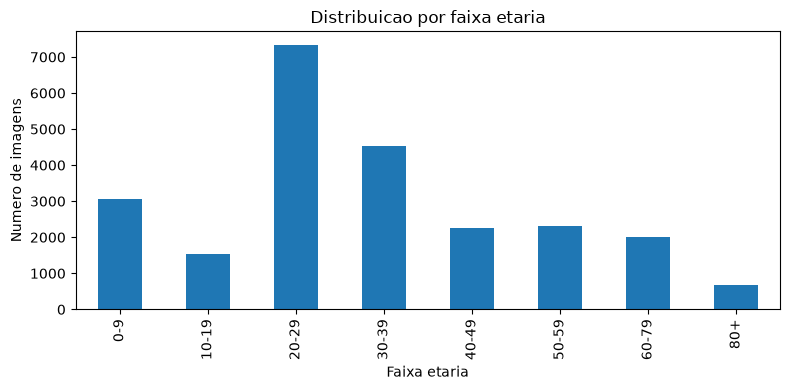

In [8]:
age_bins = [0, 10, 20, 30, 40, 50, 60, 80, 120]
age_labels = ['0-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-79', '80+']
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=False)
class_balance = df['age_group'].value_counts().sort_index()
display(class_balance.to_frame('count'))

class_balance.plot(kind='bar', figsize=(8, 4), title='Distribuicao por faixa etaria')
plt.xlabel('Faixa etaria')
plt.ylabel('Numero de imagens')
plt.tight_layout()
plt.show()

In [9]:
class AgeDataset(Dataset):
    def __init__(self, dataframe, transform=None, return_two_views=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.return_two_views = return_two_views

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(row['path']).convert('RGB')
        age = torch.tensor(float(row['age']), dtype=torch.float32)

        if self.return_two_views:
            return self.transform(image), self.transform(image), age

        if self.transform is not None:
            image = self.transform(image)
        return image, age

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

invariance_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 16, IMAGE_SIZE + 16)),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.85, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

In [10]:
generator = torch.Generator().manual_seed(SEED)
train_size = int(0.70 * len(df))
val_size = int(0.15 * len(df))
test_size = len(df) - train_size - val_size
indices = torch.randperm(len(df), generator=generator).tolist()

train_df = df.iloc[indices[:train_size]].reset_index(drop=True)
val_df = df.iloc[indices[train_size:train_size + val_size]].reset_index(drop=True)
test_df = df.iloc[indices[train_size + val_size:]].reset_index(drop=True)

print(len(train_df), len(val_df), len(test_df))

16595 3556 3557


## Arquitetura, inicializacao e otimizador

A rede e uma CNN simples para regressao. Cada bloco usa convolucao 2D, Batch Normalization, ReLU e Max Pooling. A cabeca de regressao usa Dropout e uma camada linear final com uma saida escalar.

Inicializacao: Kaiming normal para convolucoes, adequada para ativacoes ReLU; pesos das camadas lineares com Xavier uniform; vieses inicializados com zero.

Funcao de perda de regressao:

$$\mathcal{L}_{reg}=\frac{1}{B}\sum_{i=1}^{B}(y_i-\hat{y}_i)^2.$$

Otimizador: AdamW, com `lr=1e-3` e `weight_decay=1e-4`. O escalonador `ReduceLROnPlateau` reduz a taxa de aprendizagem quando o MAE de validacao para de melhorar. Os hiperparametros foram escolhidos por tentativa e erro guiada por valores comuns para CNNs pequenas em regressao de imagens.

In [11]:
class AgeCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            self.block(3, 32),
            self.block(32, 64),
            self.block(64, 128),
            self.block(128, 256),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.regressor = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.20),
            nn.Linear(128, 1),
        )
        self.apply(self.init_weights)

    @staticmethod
    def block(in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

    @staticmethod
    def init_weights(module):
        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')
        elif isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(self, x):
        return self.regressor(self.features(x)).squeeze(1)

In [12]:
def make_loaders(train_transform, consistency=False):
    train_dataset = AgeDataset(train_df, transform=train_transform, return_two_views=consistency)
    val_dataset = AgeDataset(val_df, transform=eval_transform)
    test_dataset = AgeDataset(test_df, transform=eval_transform)
    return (
        DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True),
        DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True),
        DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True),
    )

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, targets = [], []
    for images, ages in loader:
        images = images.to(DEVICE)
        output = model(images).cpu()
        preds.append(output)
        targets.append(ages)
    preds = torch.cat(preds)
    targets = torch.cat(targets)
    errors = preds - targets
    mae = errors.abs().mean().item()
    rmse = torch.sqrt((errors ** 2).mean()).item()
    return {'mae': mae, 'rmse': rmse}

def train_model(name, train_transform, consistency=False, supervised_two_views=False, lambda_cons=0.0, epochs=25):
    train_loader, val_loader, test_loader = make_loaders(train_transform, consistency=consistency)
    model = AgeCNN().to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
    history = []
    best_state = None
    best_val_mae = float('inf')

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        n_samples = 0
        start = time.time()

        for batch in train_loader:
            optimizer.zero_grad(set_to_none=True)

            if consistency:
                x1, x2, ages = batch
                x1, x2, ages = x1.to(DEVICE), x2.to(DEVICE), ages.to(DEVICE)
                pred1 = model(x1)
                pred2 = model(x2)
                if supervised_two_views:
                    reg_loss = 0.5 * (criterion(pred1, ages) + criterion(pred2, ages))
                else:
                    reg_loss = criterion(pred1, ages)
                cons_loss = criterion(pred1, pred2.detach())
                loss = reg_loss + lambda_cons * cons_loss
                batch_size = ages.size(0)
            else:
                images, ages = batch
                images, ages = images.to(DEVICE), ages.to(DEVICE)
                preds = model(images)
                reg_loss = criterion(preds, ages)
                cons_loss = torch.tensor(0.0, device=DEVICE)
                loss = reg_loss
                batch_size = ages.size(0)

            loss.backward()
            optimizer.step()
            running_loss += loss.item() * batch_size
            n_samples += batch_size

        val_metrics = evaluate(model, val_loader)
        scheduler.step(val_metrics['mae'])
        lr = optimizer.param_groups[0]['lr']
        train_loss = running_loss / n_samples
        history.append({
            'model': name,
            'epoch': epoch,
            'train_loss': train_loss,
            'val_mae': val_metrics['mae'],
            'val_rmse': val_metrics['rmse'],
            'lr': lr,
            'seconds': time.time() - start,
        })

        if val_metrics['mae'] < best_val_mae:
            best_val_mae = val_metrics['mae']
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

        print(f"{name} | epoch {epoch:02d} | loss={train_loss:.2f} | val_mae={val_metrics['mae']:.2f} | val_rmse={val_metrics['rmse']:.2f} | lr={lr:.2e}")

    model.load_state_dict(best_state)
    test_metrics = evaluate(model, test_loader)
    return model, pd.DataFrame(history), test_metrics

## Treinamento dos modelos

Aumente `EPOCHS` para uma avaliacao final mais robusta. Se estiver sem GPU, use `MAX_IMAGES` para validar o pipeline rapidamente e depois execute com a base completa.

In [13]:
EPOCHS = 25
LAMBDA_CONS = 0.5

experiments = {
    'baseline': {'transform': eval_transform, 'consistency': False, 'supervised_two_views': False, 'lambda_cons': 0.0},
    'data_augmentation': {'transform': invariance_transform, 'consistency': False, 'supervised_two_views': False, 'lambda_cons': 0.0},
    'consistency_regularization': {'transform': invariance_transform, 'consistency': True, 'supervised_two_views': False, 'lambda_cons': LAMBDA_CONS},
    'augmentation_plus_consistency': {'transform': invariance_transform, 'consistency': True, 'supervised_two_views': True, 'lambda_cons': LAMBDA_CONS},
}

# consistency_regularization usa duas vistas para impor f(T1(x)) ~= f(T2(x)),
# mas calcula a perda supervisionada apenas na primeira vista.
# augmentation_plus_consistency calcula a perda supervisionada nas duas vistas e tambem adiciona consistencia.

models = {}
histories = []
test_results = []

for name, cfg in experiments.items():
    model, history, metrics = train_model(
        name=name,
        train_transform=cfg['transform'],
        consistency=cfg['consistency'],
        supervised_two_views=cfg['supervised_two_views'],
        lambda_cons=cfg['lambda_cons'],
        epochs=EPOCHS,
    )
    models[name] = model
    histories.append(history)
    test_results.append({'model': name, **metrics})

history_df = pd.concat(histories, ignore_index=True)
results_df = pd.DataFrame(test_results).sort_values('mae')
results_df

baseline | epoch 01 | loss=279.26 | val_mae=9.48 | val_rmse=12.27 | lr=1.00e-03
baseline | epoch 02 | loss=154.58 | val_mae=8.58 | val_rmse=11.51 | lr=1.00e-03
baseline | epoch 03 | loss=132.50 | val_mae=10.03 | val_rmse=12.92 | lr=1.00e-03
baseline | epoch 04 | loss=114.74 | val_mae=10.21 | val_rmse=14.00 | lr=1.00e-03
baseline | epoch 05 | loss=106.90 | val_mae=9.17 | val_rmse=11.70 | lr=1.00e-03
baseline | epoch 06 | loss=95.62 | val_mae=9.42 | val_rmse=11.82 | lr=5.00e-04
baseline | epoch 07 | loss=80.11 | val_mae=6.49 | val_rmse=8.92 | lr=5.00e-04
baseline | epoch 08 | loss=74.49 | val_mae=6.60 | val_rmse=9.00 | lr=5.00e-04
baseline | epoch 09 | loss=70.33 | val_mae=7.73 | val_rmse=10.71 | lr=5.00e-04
baseline | epoch 10 | loss=67.35 | val_mae=6.38 | val_rmse=8.79 | lr=5.00e-04
baseline | epoch 11 | loss=59.09 | val_mae=6.42 | val_rmse=8.70 | lr=5.00e-04
baseline | epoch 12 | loss=56.53 | val_mae=6.83 | val_rmse=9.14 | lr=5.00e-04
baseline | epoch 13 | loss=49.96 | val_mae=7.05 | 

,model,mae,rmse
3,augmentation_plus_consistency,5.694439,7.951365
2,consistency_regularization,5.697783,7.897208
1,data_augmentation,5.895946,8.195981
0,baseline,6.286603,8.716240


**Observacao importante sobre os modelos com consistencia**

Para separar estritamente os tres metodos pedidos, pode-se interpretar `data_augmentation` como invariancia implicita, `consistency_regularization` como invariancia explicita via penalizacao entre duas vistas, e `augmentation_plus_consistency` como o caso em que a perda supervisionada e calculada nas duas vistas aumentadas e, alem disso, ha penalizacao explicita de consistencia. Essa ultima configuracao tende a ser a mais forte, mas tambem pode suavizar demais as predicoes se `lambda_cons` for muito alto.

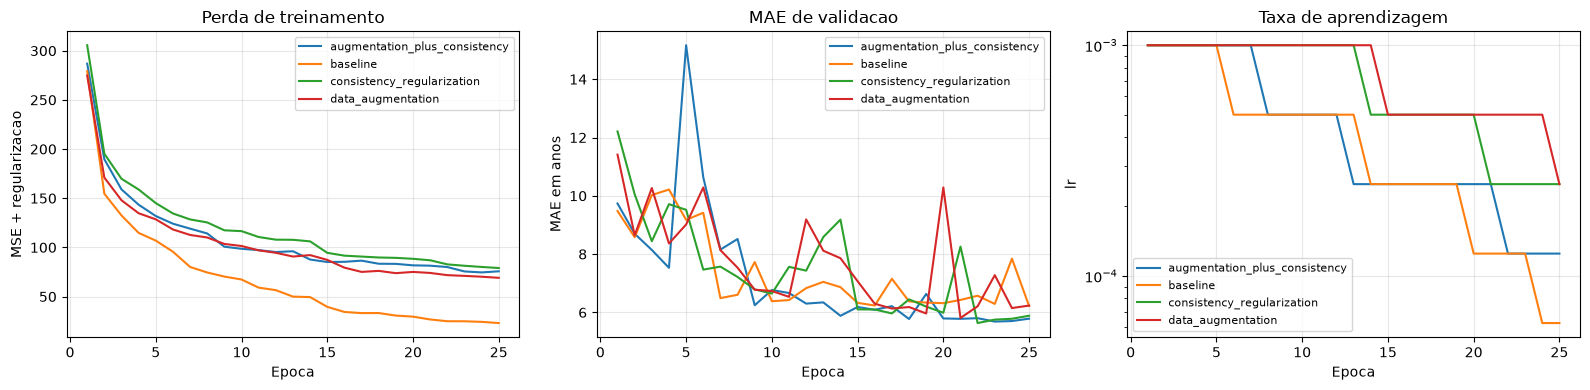

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for name, group in history_df.groupby('model'):
    axes[0].plot(group['epoch'], group['train_loss'], label=name)
    axes[1].plot(group['epoch'], group['val_mae'], label=name)
    axes[2].plot(group['epoch'], group['lr'], label=name)

axes[0].set_title('Perda de treinamento')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('MSE + regularizacao')

axes[1].set_title('MAE de validacao')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('MAE em anos')

axes[2].set_title('Taxa de aprendizagem')
axes[2].set_xlabel('Epoca')
axes[2].set_ylabel('lr')
axes[2].set_yscale('log')

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

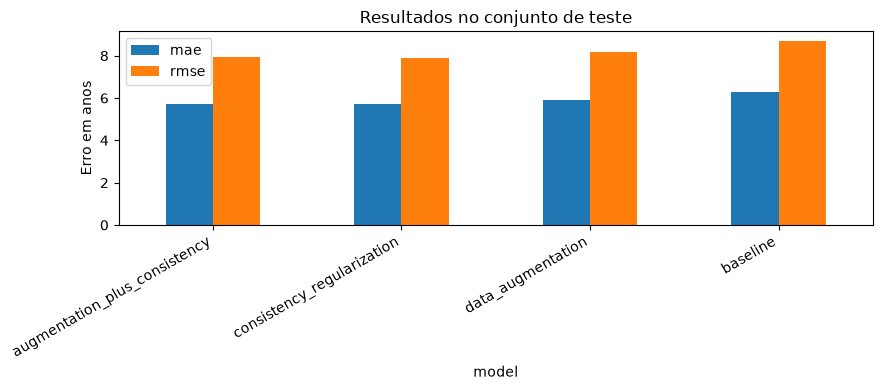

,model,mae,rmse
3,augmentation_plus_consistency,5.694439,7.951365
2,consistency_regularization,5.697783,7.897208
1,data_augmentation,5.895946,8.195981
0,baseline,6.286603,8.716240


In [15]:
results_df.plot(x='model', y=['mae', 'rmse'], kind='bar', figsize=(9, 4), title='Resultados no conjunto de teste')
plt.ylabel('Erro em anos')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

results_df

## Discussao esperada dos resultados

O baseline serve como referencia sem imposicao explicita de invariancia. O modelo com data augmentation deve reduzir overfitting e melhorar a generalizacao, pois aprende que pequenas variacoes geometricas e fotometricas nao alteram a idade. O modelo com consistency regularization adiciona uma restricao funcional mais direta: duas vistas da mesma face devem gerar idades semelhantes.

Ao analisar os graficos, espera-se que modelos com invariancia tenham perda de treinamento possivelmente maior que o baseline, porque recebem exemplos mais dificeis e/ou termo extra de regularizacao. Entretanto, se a invariancia escolhida for adequada, o MAE e o RMSE de validacao e teste devem diminuir. Caso o RMSE diminua menos que o MAE, isso indica que ainda ha erros grandes em alguns grupos, possivelmente idosos ou criancas, que costumam ter menos amostras na base.

A melhor configuracao deve ser escolhida pelo menor MAE de validacao/teste, mas tambem observando estabilidade da curva de aprendizagem. Se `augmentation_plus_consistency` piorar, a explicacao provavel e excesso de regularizacao ou transformacoes fortes demais, que podem remover sinais relevantes de idade, como rugas finas e textura da pele.

## Conclusao

A teoria de invariancia foi aplicada tratando idade como uma propriedade preservada por transformacoes pequenas da imagem facial. Foram implementadas tres estrategias: aumento de dados, regularizacao de consistencia e combinacao de ambas. A comparacao por MAE e RMSE permite verificar se a restricao de invariancia melhora a capacidade de generalizacao da CNN para estimativa de idade.